# Practical 9 - KNN

In this practical I use the iris dataset and build a KNN (K-Nearest Neighbors) model. KNN predicts the species of a flower by looking at the K closest flowers in the training data and going with the species that appears most among them.

Importing the libraries. The iris data comes with scikit-learn, so I don't need a separate file.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

### Step 1: EDA - head(), describe(), groupby()

Loading the data and adding a species column so it is easier to read.

In [2]:
iris = load_iris(as_frame=True)
df = iris.data.copy()
df["species"] = iris.target_names[iris.target]

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


describe() gives the basic summary of each measurement.

In [3]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


groupby() lets me compare the species. This is the average of each measurement for each species.

In [4]:
df.groupby("species").mean()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


Setosa has much smaller petals than the other two. Versicolor and virginica are closer to each other, so those two are the ones the model might mix up.

### Step 2: Feature scaling

KNN works on distances, so a feature with bigger numbers would count for more than the others. Scaling puts all the features on the same scale. I split the data first and fit the scaler only on the training part.

In [5]:
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training size:", X_train.shape[0], "| Test size:", X_test.shape[0])

Training size: 120 | Test size: 30


### Step 3: Training the K-NN model on the training set

I start with K = 5. A better K is searched for later.

In [6]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

### Step 4: Confusion matrix and accuracy score

The classes are 0 = setosa, 1 = versicolor, 2 = virginica. The numbers on the diagonal are the correct predictions.

[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]


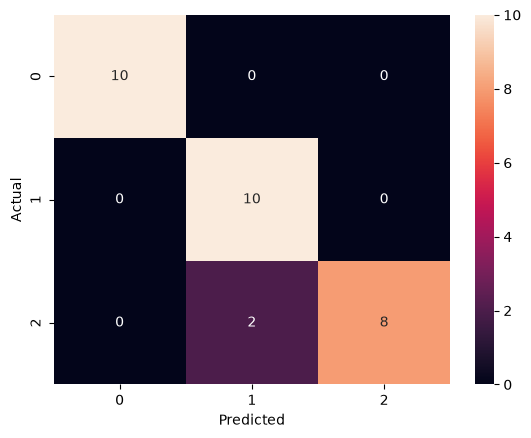

Accuracy score: 0.9333


In [7]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

sns.heatmap(cm, annot=True)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print("Accuracy score:", round(accuracy_score(y_test, y_pred), 4))

Accuracy is about 93%. All the setosa flowers are correct, and the only mistakes are 2 virginica flowers that were predicted as versicolor.

### Step 5: Classification report

In [8]:
print(classification_report(y_test, y_pred, target_names=iris.target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



Precision and recall are lower for versicolor and virginica because of those 2 mistakes. Setosa is perfect.

### Step 6: Comparing error rate with the K value

I try K from 1 to 25 and save the error rate (1 - accuracy) on the test set for each one.

In [9]:
k_values = range(1, 26)
error_rates = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    pred_k = model.predict(X_test_scaled)
    error_rates.append(1 - accuracy_score(y_test, pred_k))

error_df = pd.DataFrame({"K": list(k_values), "Error rate": np.round(error_rates, 4)})
error_df

,K,Error rate
0,1,0.0333
1,2,0.0667
2,3,0.0667
3,4,0.0667
4,5,0.0667
5,6,0.0667
6,7,0.0333
7,8,0.0667
8,9,0.0333
9,10,0.0333


### Step 7: Plot the error values against K values

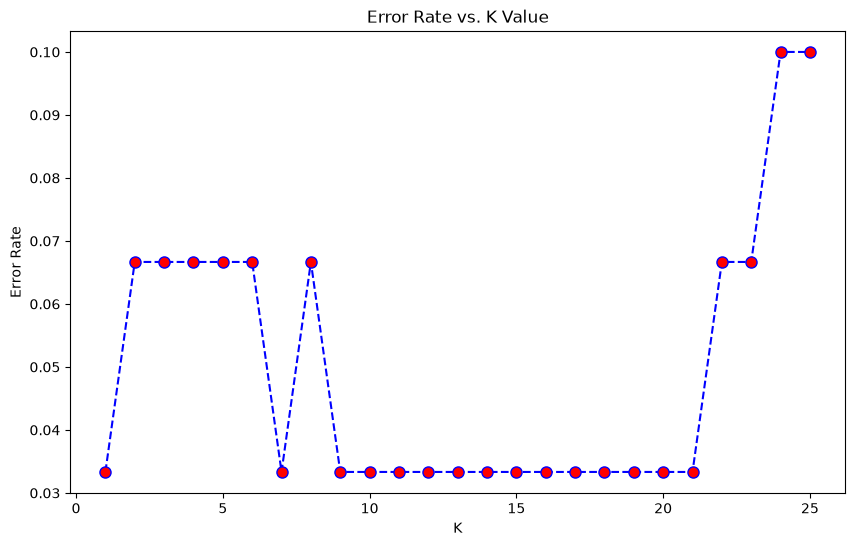

In [10]:
plt.figure(figsize=(10,6))
plt.plot(list(k_values), error_rates, color="blue", linestyle="dashed", marker="o",
         markerfacecolor="red", markersize=8)
plt.title("Error Rate vs. K Value")
plt.xlabel("K")
plt.ylabel("Error Rate")
plt.show()

The error is low (about 3% to 7%) for most K values, and it goes up after K = 21.

### Step 8: Finding the best K

I only check odd values of K, because odd numbers avoid ties when the neighbors vote. Many K values give the same lowest error, so instead of taking K = 1 (which is too sensitive to single points) I take the middle one from those.

In [11]:
odd_ks = [k for k in k_values if k % 2 == 1]
odd_errors = {k: error_rates[k - 1] for k in odd_ks}

min_error = min(odd_errors.values())
best_ks = [k for k, e in odd_errors.items() if e == min_error]
best_k = best_ks[len(best_ks) // 2]

print("Lowest error rate:", round(min_error, 4))
print("K values that reach it:", best_ks)
print("Best K chosen:", best_k)

Lowest error rate: 0.0333
K values that reach it: [1, 7, 9, 11, 13, 15, 17, 19, 21]
Best K chosen: 13


Training the model again with the best K and checking the result.

In [12]:
best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train_scaled, y_train)
best_pred = best_knn.predict(X_test_scaled)

print("Accuracy with K =", best_k, ":", round(accuracy_score(y_test, best_pred), 4))
print()
print(classification_report(y_test, best_pred, target_names=iris.target_names))

Accuracy with K = 13 : 0.9667

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



### Step 9: Test result of KNN

With K = 13 the model gets about 97% accuracy on the test set, which means 29 out of the 30 test flowers are predicted correctly.

## Conclusion

KNN works very well on the iris data. After scaling the features, the model got about 93% accuracy with K = 5 and about 97% with the best K of 13. Setosa is always classified correctly, and the few mistakes are between versicolor and virginica, which have similar measurements.